# Práctica 2: Análisis Exploratorio de Datos (EDA) y Preparación de Datasets

## 1. Comprensión del dominio del dataset

Como etapa inicial, el objetivo es entender el contexto del problema y la naturaleza de la información. Se analiza de qué trata el conjunto de datos, se revisa el diccionario de variables para comprender qué representa cada columna y se define el propósito principal del proyecto (qué fenómeno se busca explicar o predecir).


### 1.1 Dataset 1: Titanic
Variable objetivo: Supervivencia
* ¿Qué representa cada fila? Representa a un pasajero individual que viajaba a bordo del Titanic (incluye sus características como edad, sexo, tarifa pagada y clase en la que viajaba).
* ¿La variable objetivo estaría disponible en un escenario real? No antes del suceso. La supervivencia se conoce solo después de que ocurre el desastre.
* ¿Existen identificadores o variables con fuga de información? Sí. El `PassengerId`, `Name` y `Ticket` son identificadores que no aportan valor predictivo y deben descartarse.
* ¿Qué decisiones podrían afectar de forma desigual a distintos grupos? El modelo aprenderá sesgos históricos ("mujeres y niños primero", prioridad a la Primera Clase). Usar esto hoy crearía un modelo que discrimina por género o estatus socioeconómico.



### 1.2 Dataset 2: Telco Customer Churn
Variable objetivo: Abandono 
* ¿Qué representa cada fila? Representa a un cliente individual de la empresa de telecomunicaciones y los servicios que tiene contratados.
* ¿La variable objetivo estaría disponible en un escenario real? Sí y no. Tenemos el dato histórico de quién canceló, pero para predecir el futuro, esta variable es justo la que no tenemos y queremos adivinar.
* ¿Existen identificadores o variables con fuga de información? Sí, el `customerID` es un identificador único que debe eliminarse. 
* ¿Qué decisiones podrían afectar de forma desigual a distintos grupos? Variables como `SeniorCitizen` (Tercera edad) o el género podrían sesgar al modelo para clasificar injustamente a ciertos grupos demográficos como "clientes riesgosos".

### 1.3 Carga de Datasets


In [2]:
import pandas as pd

# Cargar datos usando rutas relativas
df_titanic = pd.read_csv('../data/raw/titanic.csv')
df_telco = pd.read_csv('../data/raw/Telco-Customer-Churn.csv')

print(f"Titanic cargado: {df_titanic.shape[0]} filas.")
print(f"Telco cargado: {df_telco.shape[0]} filas.")

Titanic cargado: 891 filas.
Telco cargado: 7043 filas.


## 2. Data Profiling

En esta sección se realiza un perfilado de los datos para diagnosticar su calidad general. Esto consiste en identificar los tipos de variables (numéricas, categóricas, etc.), calcular los porcentajes de valores nulos o faltantes, contar los valores únicos y generar estadísticas descriptivas básicas para tener una primera impresión de su estructura.

### 2.1 Función que genera un reporte de Data Profiling.
Calcula nulos, valores únicos y tipos de datos.

In [3]:
import pandas as pd

def hacer_profiling(df):
    # 1. Información básica
    profiling = pd.DataFrame(df.dtypes, columns=['Tipo_de_Dato'])
    
    # 2. Conteo y porcentaje de valores nulos (ausentes)
    profiling['Valores_Nulos'] = df.isnull().sum()
    profiling['Porcentaje_Nulos_%'] = round((df.isnull().sum() / len(df)) * 100, 2)
    
    # 3. Cantidad de valores únicos
    profiling['Valores_Unicos'] = df.nunique()

    profiling = profiling.reset_index()
    profiling = profiling.rename(columns={'index': 'Columna'})
    
    return profiling.sort_values(by='Porcentaje_Nulos_%', ascending=False)

def estadisticas(df):
    stats = df.describe()
    traducciones = {
        'count': 'Conteo (datos válidos)',
        'mean': 'Media (Promedio)',
        'std': 'Desviación Estándar',
        'min': 'Mínimo',
        '25%': 'Percentil 25%',
        '50%': 'Mediana (50%)',
        '75%': 'Percentil 75%',
        'max': 'Máximo'
    }
    # Traducir filas, convertir el índice en columna y ponerle nombre
    stats = stats.rename(index=traducciones)
    stats = stats.reset_index().rename(columns={'index': 'Estadística'})
    
    return stats

#### 2.1.1 Data Profiling Titanic


In [4]:
import pandas as pd

print("\n1. Perfilado General y Valores Nulos:")
display(hacer_profiling(df_titanic))

print("\n2. Estadísticas Descriptivas (Variables Numéricas):")
display(estadisticas(df_titanic))

print("\n3. Asimetría (Skewness) de Variables Numéricas:")

skewness_titanic = df_titanic.select_dtypes(include=['float64', 'int64']).skew().reset_index()
skewness_titanic.columns = ['Variable Numérica', 'Asimetría (Skewness)']
display(skewness_titanic)

print("\n4. Verificaciones de Calidad Adicionales:")

calidad_titanic = pd.DataFrame({
    'Métrica de Calidad': ['Filas Duplicadas', 'Moda - Puerto de Embarque (Embarked)'],
    'Resultado': [df_titanic.duplicated().sum(), df_titanic['Embarked'].mode()[0]]
})
display(calidad_titanic)


1. Perfilado General y Valores Nulos:


,Columna,Tipo_de_Dato,Valores_Nulos,Porcentaje_Nulos_%,Valores_Unicos
10,Cabin,object,687,77.10,147
5,Age,float64,177,19.87,88
11,Embarked,object,2,0.22,3
0,PassengerId,int64,0,0.00,891
3,Name,object,0,0.00,891
2,Pclass,int64,0,0.00,3
1,Survived,int64,0,0.00,2
4,Sex,object,0,0.00,2
7,Parch,int64,0,0.00,7
6,SibSp,int64,0,0.00,7



2. Estadísticas Descriptivas (Variables Numéricas):


,Estadística,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
0,Conteo (datos válidos),891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
1,Media (Promedio),446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
2,Desviación Estándar,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
3,Mínimo,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
4,Percentil 25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
5,Mediana (50%),446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
6,Percentil 75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
7,Máximo,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



3. Asimetría (Skewness) de Variables Numéricas:


,Variable Numérica,Asimetría (Skewness)
0,PassengerId,0.000000
1,Survived,0.478523
2,Pclass,-0.630548
3,Age,0.389108
4,SibSp,3.695352
5,Parch,2.749117
6,Fare,4.787317



4. Verificaciones de Calidad Adicionales:


,Métrica de Calidad,Resultado
0,Filas Duplicadas,0
1,Moda - Puerto de Embarque (Embarked),S


#### 2.1.2 Data Profiling Telco


In [5]:
print("\n1. Perfilado General y Valores Nulos:")
display(hacer_profiling(df_telco))

print("\n2. Estadísticas Descriptivas (Variables Numéricas):")
display(estadisticas(df_telco))

print("\n3. Asimetría (Skewness) de Variables Numéricas:")

skewness_telco = df_telco.select_dtypes(include=['float64', 'int64']).skew().reset_index()
skewness_telco.columns = ['Variable Numérica', 'Asimetría (Skewness)']
display(skewness_telco)

print("\n4. Verificaciones de Calidad Adicionales:")

calidad_telco = pd.DataFrame({
    'Métrica de Calidad': ['Filas Duplicadas', 'Moda - Tipo de Contrato (Contract)'],
    'Resultado': [df_telco.duplicated().sum(), df_telco['Contract'].mode()[0]]
})
display(calidad_telco)


1. Perfilado General y Valores Nulos:


,Columna,Tipo_de_Dato,Valores_Nulos,Porcentaje_Nulos_%,Valores_Unicos
0,customerID,object,0,0.0,7043
1,gender,object,0,0.0,2
2,SeniorCitizen,int64,0,0.0,2
3,Partner,object,0,0.0,2
4,Dependents,object,0,0.0,2
5,tenure,int64,0,0.0,73
6,PhoneService,object,0,0.0,2
7,MultipleLines,object,0,0.0,3
8,InternetService,object,0,0.0,3
9,OnlineSecurity,object,0,0.0,3



2. Estadísticas Descriptivas (Variables Numéricas):


,Estadística,SeniorCitizen,tenure,MonthlyCharges
0,Conteo (datos válidos),7043.000000,7043.000000,7043.000000
1,Media (Promedio),0.162147,32.371149,64.761692
2,Desviación Estándar,0.368612,24.559481,30.090047
3,Mínimo,0.000000,0.000000,18.250000
4,Percentil 25%,0.000000,9.000000,35.500000
5,Mediana (50%),0.000000,29.000000,70.350000
6,Percentil 75%,0.000000,55.000000,89.850000
7,Máximo,1.000000,72.000000,118.750000



3. Asimetría (Skewness) de Variables Numéricas:


,Variable Numérica,Asimetría (Skewness)
0,SeniorCitizen,1.833633
1,tenure,0.239540
2,MonthlyCharges,-0.220524



4. Verificaciones de Calidad Adicionales:


,Métrica de Calidad,Resultado
0,Filas Duplicadas,0
1,Moda - Tipo de Contrato (Contract),Month-to-month


### 2.2 Hallazgos principales del Data Profiling

En el dataset Titanic:
* Valores Ausentes: La columna `Cabin` tiene un nivel crítico de datos perdidos (más del 77%), mientras que `Age` tiene casi un 20% de nulos. Estos huecos tendrán que ser imputados.
* Valores Únicos: Existen columnas como `Name` (891 únicos), `Ticket` y `PassengerId` que tienen casi tantos valores únicos como filas. Esto confirma que son identificadores y no sirven para el modelo.

En el dataset Telco Customer Churn:
* Tipos de datos incorrectos: La columna `TotalCharges` (Cargos Totales) debería ser numérica, pero el profiling indica que es de tipo "object" (texto). Esto es un problema común puesto que a veces hay espacios en blanco ocultos que impiden a Python leerlo como número, por lo que habrá que forzar su conversión.
* Valores Ausentes: A simple vista parece que Telco no tiene valores nulos, pero el error de tipo de dato en `TotalCharges` esconde que los espacios en blanco son en realidad datos faltantes.

## 3. Análisis Exploratorio (EDA)

Es la fase de investigación profunda visual y estadística. Aquí se examina cómo se distribuyen los datos, se detectan valores atípicos (outliers) que puedan alterar los modelos, se evalúa cómo interactúan las variables independientes con la variable objetivo y se calculan las matrices de correlación para encontrar relaciones matemáticas o redundancias entre los datos.

### 3.1 Análisis Univariado (Distribuciones)

Se realizará visualmente el análisis de cada dataset para entender el comportamiento de las variables.

#### 3.1.1 Titanic: Distribuciones numéricas

In [6]:
# --- EDA TITANIC: DISTRIBUCIONES NUMÉRICAS ---
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración general
sns.set_theme(style="whitegrid")

# Crear una figura con 2 espacios (1 fila, 2 columnas)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Análisis Univariado: Distribuciones (Titanic)', fontsize=16)

# 1. Edad
sns.histplot(df_titanic['Age'], kde=True, ax=ax[0], color='skyblue')
ax[0].set_title('¿Cuál es el rango de edad predominante?')

# 2. Tarifa pagada (Fare)
sns.histplot(df_titanic['Fare'], bins=40, kde=True, ax=ax[1], color='lightgreen')
ax[1].set_title('¿Cómo se distribuyen las tarifas pagadas?')

plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'seaborn'

##### Hallazgos de las variables numéricas

Edad: La distribución tiene un sesgo positivo leve, donde la gran mayoría de los pasajeros tenían entre 20 y 30 años. Se observa también un pequeño pico en edades muy tempranas (niños pequeños).

Tarifa (Fare): La distribución está fuertemente sesgada a la derecha. La inmensa mayoría de los pasajeros pagó tarifas muy bajas (correspondientes a 3ra clase), mientras que unos pocos pagaron tarifas altísimas (valores atípicos o de 1ra clase).

#### 3.1.2 Titanic: Variables catégoricas y clases

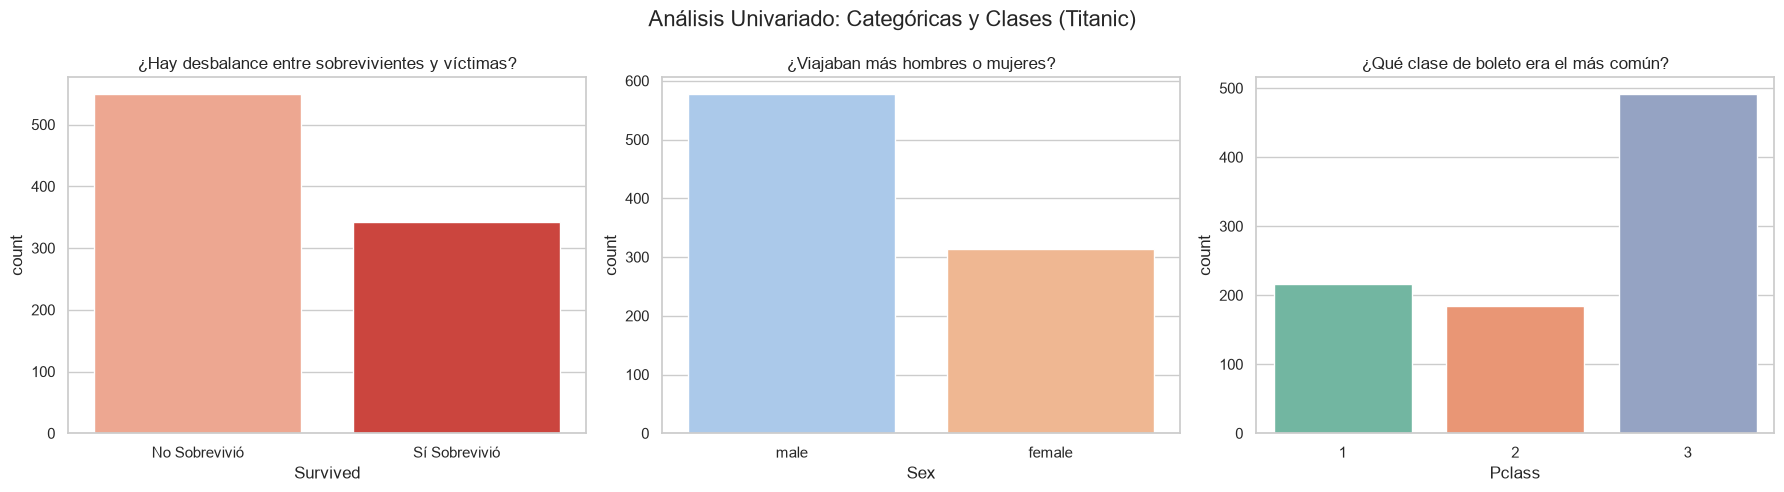

In [ ]:
# --- EDA TITANIC: VARIABLES CATEGÓRICAS Y CLASES ---

# Crear una figura con 3 espacios (1 fila, 3 columnas)
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Análisis Univariado: Categóricas y Clases (Titanic)', fontsize=16)

# 1. Distribución de Clases (Barras)
sns.countplot(x='Survived', data=df_titanic, ax=ax[0], hue='Survived', palette='Reds', legend=False)
ax[0].set_title('¿Hay desbalance entre sobrevivientes y víctimas?')
ax[0].set_xticks([0, 1])
ax[0].set_xticklabels(['No Sobrevivió', 'Sí Sobrevivió'])

# 2. Género (Barras)
sns.countplot(x='Sex', data=df_titanic, ax=ax[1], hue='Sex', palette='pastel', legend=False)
ax[1].set_title('¿Viajaban más hombres o mujeres?')

# 3. Clase del pasajero (Pclass)
sns.countplot(x='Pclass', data=df_titanic, ax=ax[2], hue='Pclass', palette='Set2', legend=False)
ax[2].set_title('¿Qué clase de boleto era el más común?')

plt.tight_layout()
plt.show()

##### Hallazgos de las variables categóricas

Supervivencia: Existe un desbalance de clases evidente; murieron muchas más personas de las que sobrevivieron.

Género: Había una proporción significativamente mayor de hombres que de mujeres a bordo.

Clase: La tercera clase era, por mucho, la más concurrida, superando a la suma de la primera y segunda clase juntas.

#### 3.1.3 Telco: Distribuciones numéricas

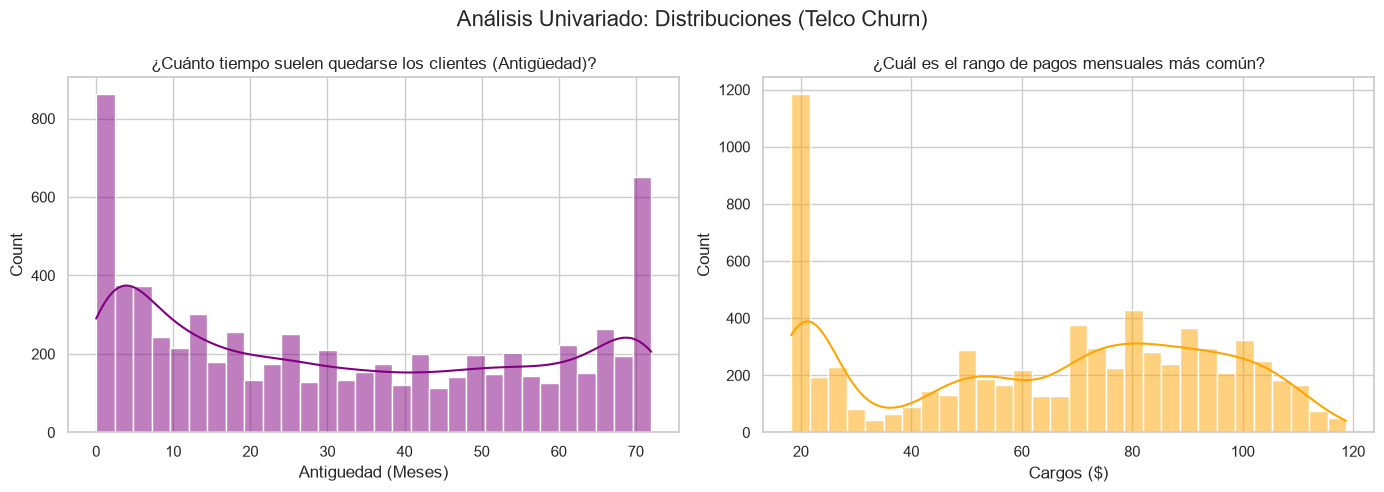

In [ ]:
# --- EDA TELCO: DISTRIBUCIONES NUMÉRICAS ---
import matplotlib.pyplot as plt
import seaborn as sns

# Crear figura con 2 espacios
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Análisis Univariado: Distribuciones (Telco Churn)', fontsize=16)

# Convertir 'TotalCharges' a número por si acaso
df_telco['TotalCharges'] = pd.to_numeric(df_telco['TotalCharges'], errors='coerce')

# 1. Antigüedad (Tenure)
sns.histplot(df_telco['tenure'], bins=30, kde=True, ax=ax[0], color='purple')
ax[0].set_title('¿Cuánto tiempo suelen quedarse los clientes (Antigüedad)?')
ax[0].set_xlabel('Antiguedad (Meses)')

# 2. Cargos Mensuales
sns.histplot(df_telco['MonthlyCharges'], bins=30, kde=True, ax=ax[1], color='orange')
ax[1].set_title('¿Cuál es el rango de pagos mensuales más común?')
ax[1].set_xlabel('Cargos ($)')

plt.tight_layout()
plt.show()

##### Hallazgos de las variables numéricas

Antigüedad (Tenure): La distribución tiene un comportamiento bimodal (forma de U). Hay un volumen muy alto de clientes en sus primeros meses (clientes nuevos o con alta rotación) y otro pico importante en el extremo derecho, lo que indica un grupo sólido de clientes muy leales (más de 70 meses).

Cargos Mensuales (MonthlyCharges): Existe un pico muy marcado en el extremo inferior (alrededor de los $20), lo que sugiere que una gran parte de la base de clientes solo contrata el servicio más básico. El resto de la distribución es más uniforme, representando a usuarios con paquetes de servicios combinados.

#### 3.1.4 Telco: Variables catégoricas y clases

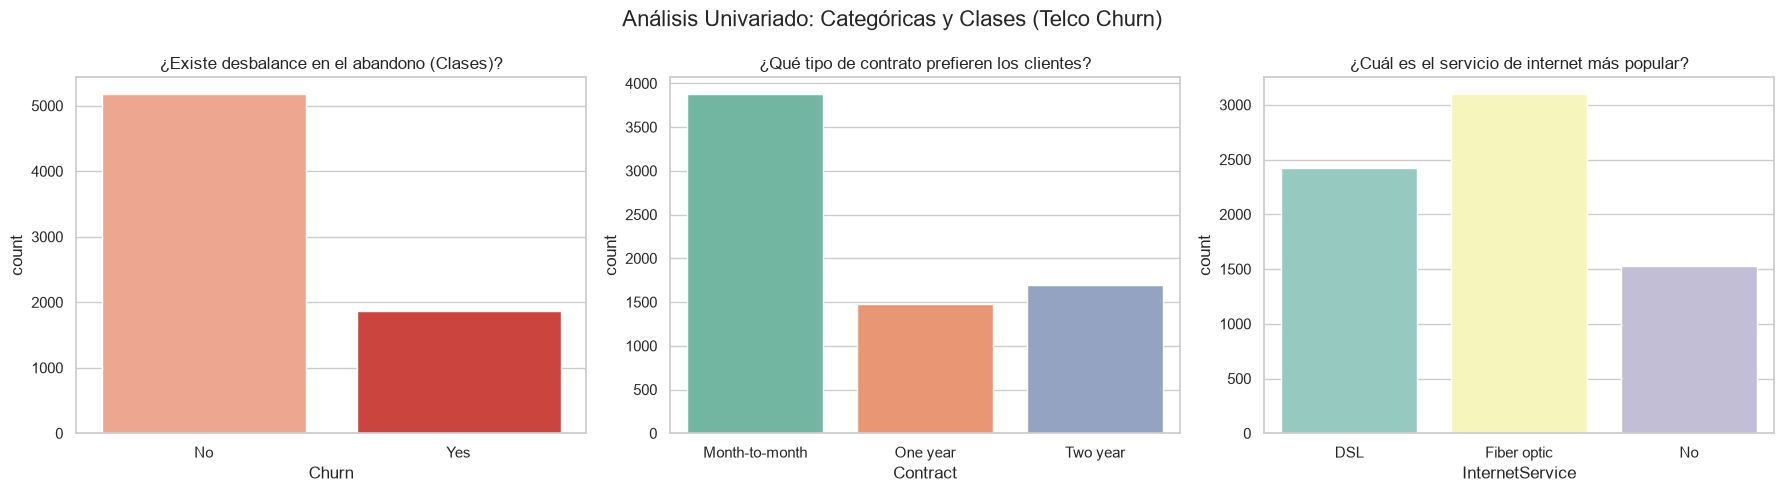

In [ ]:
# --- EDA TELCO: VARIABLES CATEGÓRICAS Y CLASES ---
# Crear figura con 3 espacios
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Análisis Univariado: Categóricas y Clases (Telco Churn)', fontsize=16)

# 1. Distribución de Clases (Churn)
sns.countplot(x='Churn', data=df_telco, ax=ax[0], hue='Churn', palette='Reds', legend=False)
ax[0].set_title('¿Existe desbalance en el abandono (Clases)?')

# 2. Tipo de Contrato
sns.countplot(x='Contract', data=df_telco, ax=ax[1], hue='Contract', palette='Set2', legend=False)
ax[1].set_title('¿Qué tipo de contrato prefieren los clientes?')

# 3. Servicio de Internet
sns.countplot(x='InternetService', data=df_telco, ax=ax[2], hue='InternetService', palette='Set3', legend=False)
ax[2].set_title('¿Cuál es el servicio de internet más popular?')

plt.tight_layout()
plt.show()

##### Hallazgos de las variables categóricas 

Fuga (Churn): Al igual que la supervivencia en el Titanic, aquí también hay un desbalance. La mayoría de los clientes permanece en la empresa, pero hay una proporción considerable (aprox. el 26%) que abandona el servicio.

Contrato (Contract): Los contratos de "Mes a mes" (Month-to-month) son, por mucho, los más comunes, seguidos de los contratos a dos años.

Servicio de Internet: La fibra óptica es el servicio más popular entre los clientes, superando al DSL, aunque también hay un grupo que no cuenta con servicio de internet.

### 3.2 Análisis Bivariado y Correlación
Análisis para detectar valores atípicos mediante Boxplots y observar la relación entre los atributos y la variable objetivo.

#### 3.2.1 Titanic: Boxplots y relación atributo - objetivo

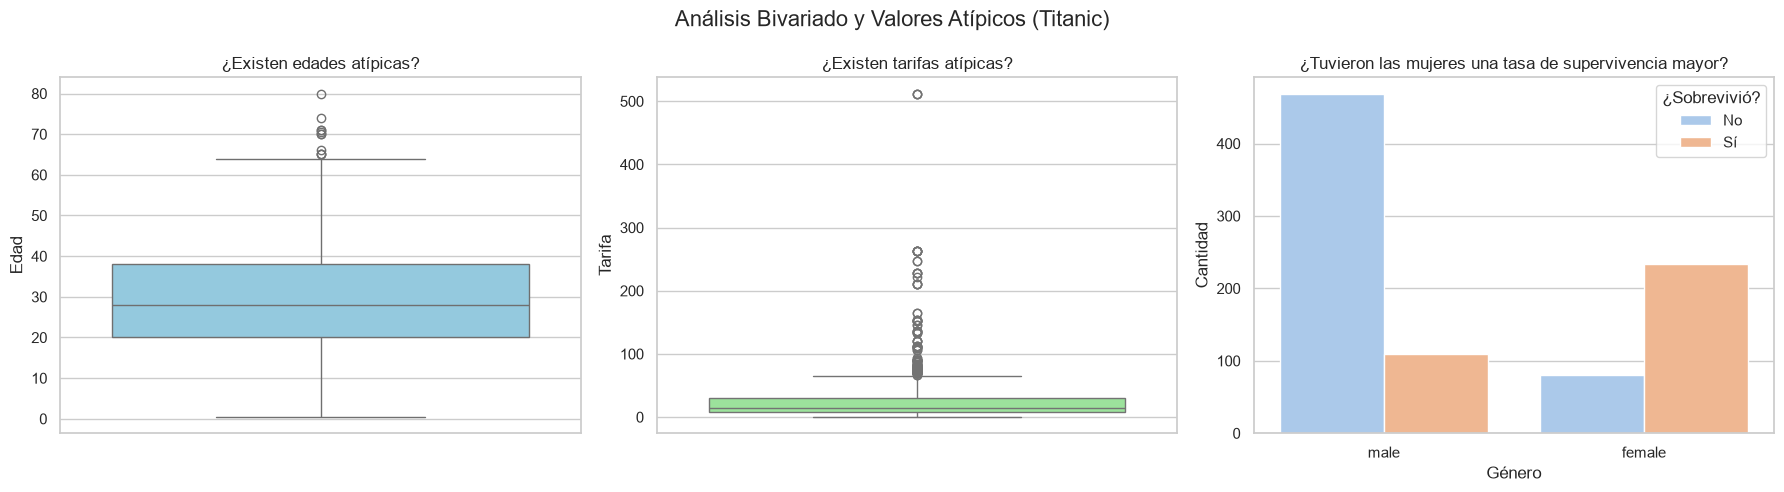

In [ ]:
# --- EDA TITANIC: BOXPLOTS Y RELACIÓN ATRIBUTO-OBJETIVO ---
import matplotlib.pyplot as plt
import seaborn as sns

# Figura con 3 espacios
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Análisis Bivariado y Valores Atípicos (Titanic)', fontsize=16)

# 1. Boxplot de la Edad
sns.boxplot(y='Age', data=df_titanic, ax=ax[0], color='skyblue')
ax[0].set_title('¿Existen edades atípicas?')
ax[0].set_ylabel('Edad')

# 2. Boxplot de la Tarifa (Fare)
sns.boxplot(y='Fare', data=df_titanic, ax=ax[1], color='lightgreen')
ax[1].set_title('¿Existen tarifas atípicas?')
ax[1].set_ylabel('Tarifa')

# 3. Relación Atributo-Objetivo (Supervivencia vs Género)
sns.countplot(x='Sex', hue='Survived', data=df_titanic, ax=ax[2], palette='pastel')
ax[2].set_title('¿Tuvieron las mujeres una tasa de supervivencia mayor?')
ax[2].set_xlabel('Género')
ax[2].set_ylabel('Cantidad')
ax[2].legend(title='¿Sobrevivió?', labels=['No', 'Sí'])

plt.tight_layout()
plt.show()

##### Hallazgos del análisis bivariado y valores atípicos
Edad: La mayoría de los pasajeros tenían entre 20 y 38 años, con una mediana de 28 años. Se identifican valores atípicos que corresponden a un pequeño grupo de personas mayores, llegando hasta los 80 años.   

Tarifa (Fare): La inmensa mayoría pagó tarifas muy bajas. Sin embargo, existen valores atípicos extremos con tarifas muy elevadas, llegando algunas a superar el valor de 500.   

Género y Supervivencia: A pesar de que los hombres eran la mayoría a bordo, sufrieron la mayor cantidad de muertes. En contraste, la mayoría de las mujeres sobrevivió, mostrando una tasa de supervivencia significativamente mayor.  

#### 3.2.2 Titanic: Matriz de correlación

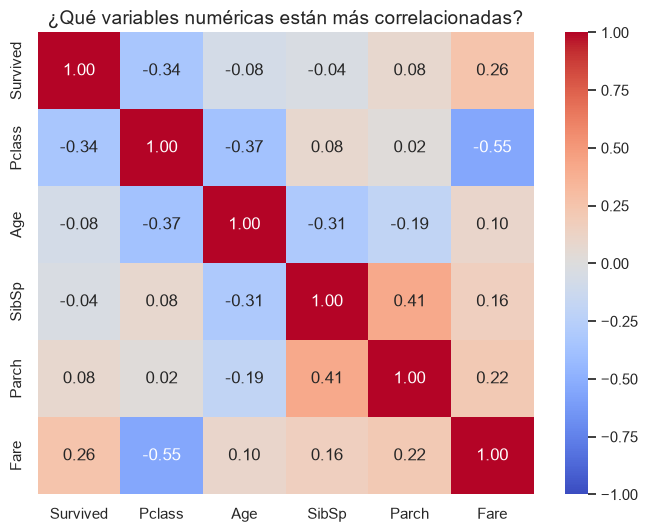

In [ ]:
# --- EDA TITANIC: MATRIZ DE CORRELACIÓN ---
plt.figure(figsize=(8, 6))

# Seleccionar solo variables numéricas para la correlación
cols_numericas = df_titanic.select_dtypes(include=['float64', 'int64']).columns

# Calcular correlación (excluyendo el PassengerId)
matriz_corr = df_titanic[cols_numericas].drop('PassengerId', axis=1, errors='ignore').corr()

sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('¿Qué variables numéricas están más correlacionadas?', fontsize=14)
plt.show()

##### Hallazgos de la matriz de correlación

Clase y Tarifa (Pclass y Fare): Existe una fuerte correlación negativa (-0.55). Esto es lógico e indica que las mejores clases (representadas con números menores, como la 1ra clase) están asociadas a tarifas más altas.

Supervivencia, Clase y Tarifa: La supervivencia (Survived) tiene una correlación negativa con la clase del pasajero (-0.34) y positiva con la tarifa (0.26). Esto confirma que los pasajeros de clases superiores (1ra clase) y aquellos que pagaron boletos más caros tuvieron mayores probabilidades de sobrevivir.

Edad y Clase (Age y Pclass): Se observa una correlación negativa moderada (-0.37). Esto sugiere que los pasajeros de las clases más exclusivas (1ra clase) tendían a ser personas de mayor edad en comparación con los de 3ra clase.

Relaciones Familiares (SibSp y Parch): Hay una correlación positiva (0.41) entre viajar con hermanos/cónyuge (SibSp) y viajar con padres/hijos (Parch). Esto indica que las personas que viajaban acompañadas solían hacerlo en grupos familiares.

#### 3.2.3 Telco: Boxplots y relación atributo - objetivo

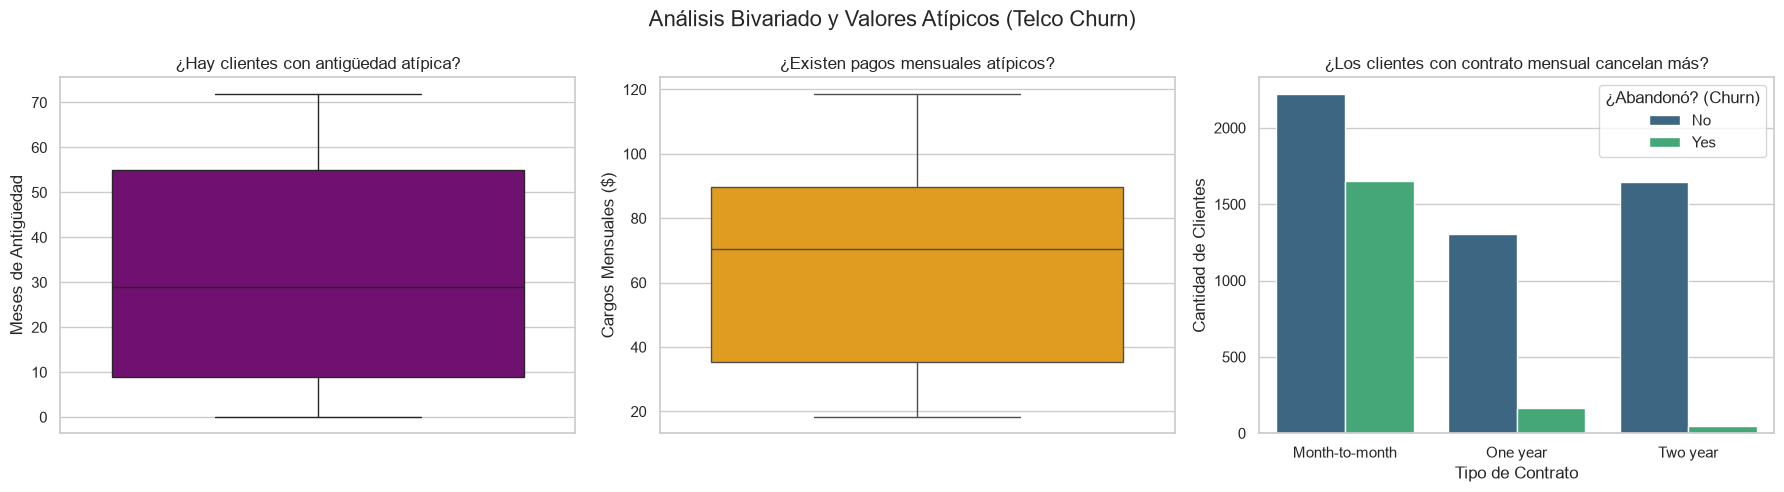

In [ ]:
# --- EDA TELCO: BOXPLOTS Y RELACIÓN ATRIBUTO-OBJETIVO ---
import matplotlib.pyplot as plt
import seaborn as sns

# Figura con 3 espacios
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Análisis Bivariado y Valores Atípicos (Telco Churn)', fontsize=16)

# 1. Boxplot Antigüedad
sns.boxplot(y='tenure', data=df_telco, ax=ax[0], color='purple')
ax[0].set_title('¿Hay clientes con antigüedad atípica?')
ax[0].set_ylabel('Meses de Antigüedad')

# 2. Boxplot Cargos Mensuales
sns.boxplot(y='MonthlyCharges', data=df_telco, ax=ax[1], color='orange')
ax[1].set_title('¿Existen pagos mensuales atípicos?')
ax[1].set_ylabel('Cargos Mensuales ($)')

# 3. Relación Atributo-Objetivo (Contrato vs Churn)
sns.countplot(x='Contract', hue='Churn', data=df_telco, ax=ax[2], palette='viridis')
ax[2].set_title('¿Los clientes con contrato mensual cancelan más?')
ax[2].set_xlabel('Tipo de Contrato')
ax[2].set_ylabel('Cantidad de Clientes')
ax[2].legend(title='¿Abandonó? (Churn)')

plt.tight_layout()
plt.show()

##### Hallazgos del análisis bivariado y valores atípicos (Telco)

Antigüedad (Tenure): La distribución de los meses de antigüedad de los clientes es amplia y abarca de manera uniforme casi todo el rango. Destaca que no existen valores atípicos; es decir, no hay clientes con tiempos de permanencia fuera del patrón normal.

Cargos Mensuales (MonthlyCharges): La mayor parte de los clientes paga entre $35 y $90 mensuales, con un promedio general cercano a los $70. Al igual que con la antigüedad, tampoco se observan valores atípicos en los cobros, todos caen dentro de un rango esperado.

Contrato y Abandono (Churn): El tipo de contrato influye drásticamente en la retención. Los clientes con contratos de mes a mes ("Month-to-month") cancelan el servicio con mucha mayor frecuencia. Por el contrario, aquellos con contratos a largo plazo (de uno o dos años) muestran gran lealtad y una tasa de abandono mínima.

#### 3.2.4 Telco: Matriz de correlación

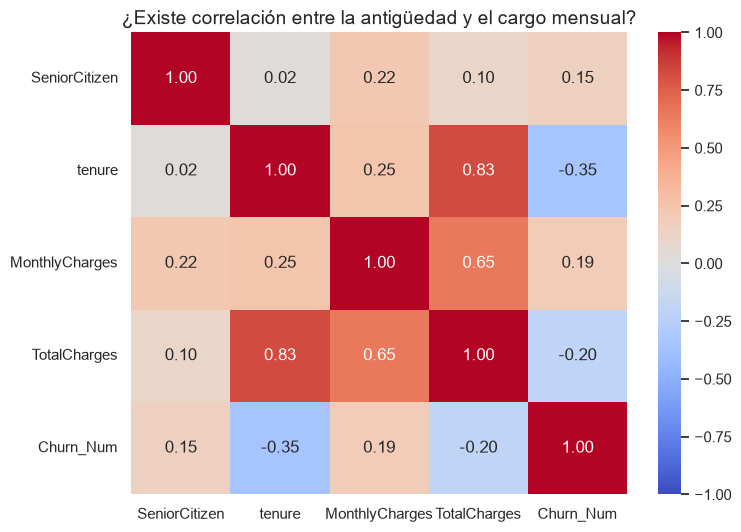

In [ ]:
# --- EDA TELCO: MATRIZ DE CORRELACIÓN ---
plt.figure(figsize=(8, 6))

# Seleccionar solo variables numéricas para la correlación

cols_numericas_telco = df_telco.select_dtypes(include=['float64', 'int64']).columns

# Calcular correlación
matriz_corr_telco = df_telco[cols_numericas_telco].corr()

sns.heatmap(matriz_corr_telco, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('¿Existe correlación entre la antigüedad y el cargo mensual?', fontsize=14)
plt.show()

##### Hallazgos de la matriz de correlación (Telco)

Antigüedad y Cargos Totales (tenure y TotalCharges): Existe una fuerte correlación positiva (0.83). Esto es un comportamiento esperado, ya que a mayor tiempo de permanencia del cliente en la empresa, mayor es la cantidad de dinero acumulada que ha pagado.

Cargos Mensuales y Cargos Totales (MonthlyCharges y TotalCharges): Se observa una correlación positiva considerable (0.65). Esto indica que los clientes con facturas mensuales más caras lógicamente acumulan montos totales más altos con el tiempo.

Antigüedad y Cargo Mensual (tenure y MonthlyCharges): Muestran una correlación débil (0.25). Respondiendo a la pregunta principal del gráfico, el tiempo que lleva un cliente en la compañía no determina de forma significativa si paga una mensualidad alta o baja.

Tercera Edad (SeniorCitizen): Esta variable tiene correlaciones muy bajas con el resto. Su relación más alta es una correlación positiva muy débil (0.22) con los cargos mensuales, lo que sugiere una ligerísima tendencia de los adultos mayores a tener planes ligeramente más costosos, pero no es determinante.

## 4. Imputación de valores perdidos

En esta sección se comparan dos estrategias de imputación para analizar su efecto
sobre la distribución de los datos y el desempeño de un clasificador.

Para Titanic se utilizarán:
- Variable numérica: `Age`
- Variable categórica: `Embarked`

Estrategia A:
- Numéricas: media
- Categóricas: moda

Estrategia B:
- Numéricas: mediana
- Categóricas: categoría "Desconocido"

También se crearán indicadores binarios para identificar las observaciones que
originalmente tenían valores ausentes.


In [13]:
# Valores faltantes de las variables seleccionadas

print("Titanic")
print(df_titanic[['Age', 'Embarked']].isnull().sum())

df_telco['TotalCharges'] = pd.to_numeric(
    df_telco['TotalCharges'],
    errors='coerce'
)

print("\nTelco")
print(df_telco[['TotalCharges']].isnull().sum())

Titanic
Age         177
Embarked      2
dtype: int64

Telco
TotalCharges    11
dtype: int64


Titanic presenta valores faltantes tanto en una variable numérica como categórica, por lo que permite comparar directamente las dos estrategias propuestas.

En Telco, `TotalCharges` presenta algunos valores faltantes después de convertirla a formato numérico. No se encontraron variables categóricas con valores ausentes, por lo que no se crearán faltantes artificialmente.
### 4.1 Imputación en Titanic

Se crearán dos copias del dataset para aplicar ambas estrategias sin modificar los datos originales.

In [14]:
titanic_A = df_titanic.copy()
titanic_B = df_titanic.copy()

media_age = df_titanic['Age'].mean()
mediana_age = df_titanic['Age'].median()
moda_embarked = df_titanic['Embarked'].mode()[0]

print(f"Media de Age: {media_age:.2f}")
print(f"Mediana de Age: {mediana_age:.2f}")
print(f"Moda de Embarked: {moda_embarked}")

Media de Age: 29.70
Mediana de Age: 28.00
Moda de Embarked: S


#### 4.1.1 Revisión de valores faltantes

In [15]:
# Indicadores de ausencia

titanic_A['Age_missing'] = titanic_A['Age'].isna().astype(int)
titanic_A['Embarked_missing'] = titanic_A['Embarked'].isna().astype(int)

titanic_B['Age_missing'] = titanic_B['Age'].isna().astype(int)
titanic_B['Embarked_missing'] = titanic_B['Embarked'].isna().astype(int)

#### 4.1.2 Preparación de las estrategias de imputación

In [16]:
# Estrategia A: media y moda

titanic_A['Age'] = titanic_A['Age'].fillna(media_age)
titanic_A['Embarked'] = titanic_A['Embarked'].fillna(moda_embarked)

# Estrategia B: mediana y Desconocido

titanic_B['Age'] = titanic_B['Age'].fillna(mediana_age)
titanic_B['Embarked'] = titanic_B['Embarked'].fillna('Desconocido')

#### 4.1.3 Aplicación de las estrategias A y B

In [17]:
print("Faltantes Estrategia A")
print(titanic_A[['Age', 'Embarked']].isnull().sum())

print("\nFaltantes Estrategia B")
print(titanic_B[['Age', 'Embarked']].isnull().sum())

Faltantes Estrategia A
Age         0
Embarked    0
dtype: int64

Faltantes Estrategia B
Age         0
Embarked    0
dtype: int64


Después de aplicar ambas estrategias ya no existen valores faltantes en `Age` y `Embarked`.
### 4.1.4 Comparación de la variable Age

Se comparan las estadísticas antes y después de la imputación para observar el efecto de ambas estrategias.

In [18]:
comparacion_age = pd.DataFrame({
    'Original': [
        df_titanic['Age'].mean(),
        df_titanic['Age'].median(),
        df_titanic['Age'].var(),
        df_titanic['Age'].std()
    ],
    'Media': [
        titanic_A['Age'].mean(),
        titanic_A['Age'].median(),
        titanic_A['Age'].var(),
        titanic_A['Age'].std()
    ],
    'Mediana': [
        titanic_B['Age'].mean(),
        titanic_B['Age'].median(),
        titanic_B['Age'].var(),
        titanic_B['Age'].std()
    ]
}, index=['Media', 'Mediana', 'Varianza', 'Desviación estándar'])

display(comparacion_age.round(2))

,Original,Media,Mediana
Media,29.70,29.70,29.36
Mediana,28.00,29.70,28.00
Varianza,211.02,169.05,169.51
Desviación estándar,14.53,13.00,13.02


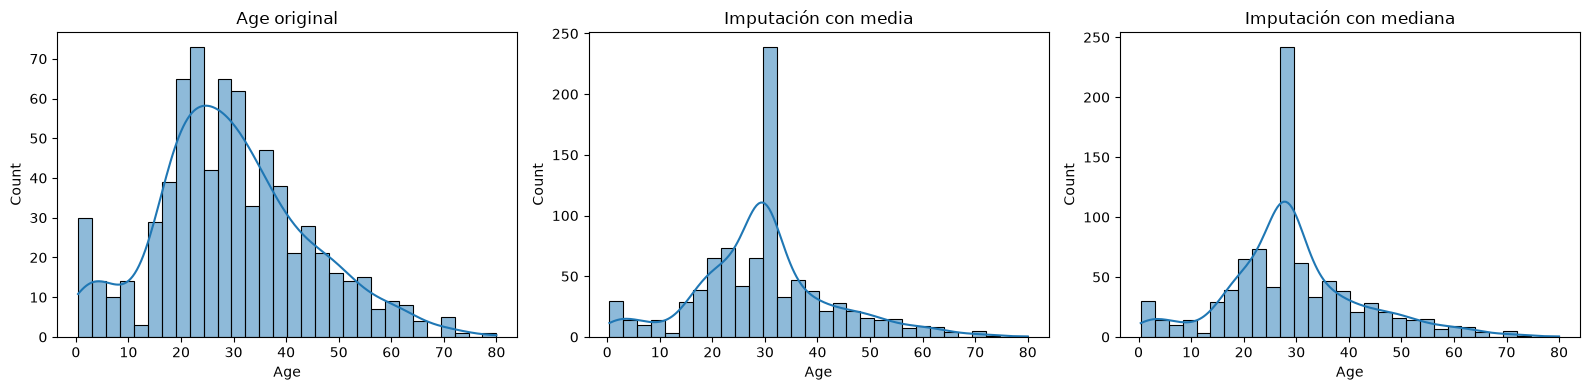

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df_titanic['Age'], bins=30, kde=True, ax=axes[0])
axes[0].set_title('Age original')

sns.histplot(titanic_A['Age'], bins=30, kde=True, ax=axes[1])
axes[1].set_title('Imputación con media')

sns.histplot(titanic_B['Age'], bins=30, kde=True, ax=axes[2])
axes[2].set_title('Imputación con mediana')

plt.tight_layout()
plt.show()

Ambas estrategias generan una concentración de observaciones alrededor del valor utilizado para imputar.

También se observa una reducción de la varianza respecto a los datos originales, ya que varios registros reciben exactamente el mismo valor. La mediana es menos sensible a valores extremos que la media.
### 4.1.5 Comparación de la variable Embarked

Para la variable categórica se compara la imputación mediante moda contra la creación de una nueva categoría llamada `Desconocido`.

,Original,Moda,Desconocido
Embarked,,,
C,168.0,168.0,168.0
Desconocido,0.0,0.0,2.0
Q,77.0,77.0,77.0
S,644.0,646.0,644.0
NaN,2.0,0.0,0.0


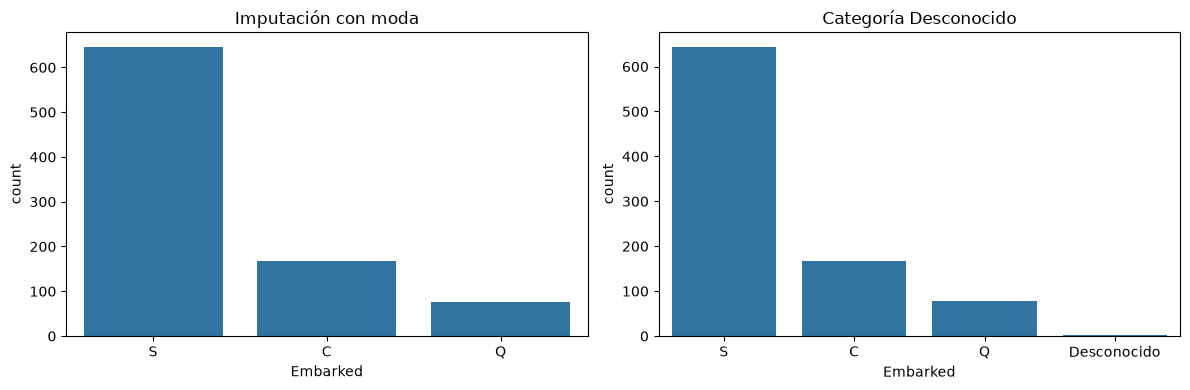

In [25]:
comparacion_embarked = pd.DataFrame({
    'Original': df_titanic['Embarked'].value_counts(dropna=False),
    'Moda': titanic_A['Embarked'].value_counts(dropna=False),
    'Desconocido': titanic_B['Embarked'].value_counts(dropna=False)
}).fillna(0)

display(comparacion_embarked)
#Graficas
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=titanic_A, x='Embarked', ax=axes[0])
axes[0].set_title('Imputación con moda')

sns.countplot(data=titanic_B, x='Embarked', ax=axes[1])
axes[1].set_title('Categoría Desconocido')

plt.tight_layout()
plt.show()

La imputación mediante moda agrega los valores faltantes a la categoría más frecuente (`S`).

La segunda estrategia conserva los casos faltantes como una categoría independiente. Como solamente existen dos valores ausentes, el cambio en la distribución es pequeño.
### 4.1.6 Indicador de valor ausente

Se analiza si el hecho de que `Age` estuviera ausente presenta alguna relación con la variable objetivo.

In [26]:
analisis_missing = (
    titanic_A
    .groupby('Age_missing')['Survived']
    .agg(['count', 'mean'])
)

display(analisis_missing)

,count,mean
Age_missing,,
0,714,0.406162
1,177,0.293785


Los pasajeros con edad registrada y aquellos con edad ausente presentan diferentes tasas de supervivencia.

Esto sugiere que la ausencia de `Age` podría contener información útil, por lo que se conserva el indicador `Age_missing`.
### 4.2 Imputación en Telco Customer Churn

En Telco se comparan media y mediana para `TotalCharges`. No se encontraron variables categóricas con valores faltantes.

In [27]:
telco_A = df_telco.copy()
telco_B = df_telco.copy()

telco_A['TotalCharges_missing'] = telco_A['TotalCharges'].isna().astype(int)
telco_B['TotalCharges_missing'] = telco_B['TotalCharges'].isna().astype(int)

media_total = df_telco['TotalCharges'].mean()
mediana_total = df_telco['TotalCharges'].median()

print(f"Media: {media_total:.2f}")
print(f"Mediana: {mediana_total:.2f}")

Media: 2283.30
Mediana: 1397.47


#### 4.2.1 Revisión de valores faltantes en TotalCharges

In [28]:
telco_A['TotalCharges'] = telco_A['TotalCharges'].fillna(media_total)
telco_B['TotalCharges'] = telco_B['TotalCharges'].fillna(mediana_total)

#### 4.2.2 Aplicación de media y mediana

In [29]:
comparacion_total = pd.DataFrame({
    'Original': [
        df_telco['TotalCharges'].mean(),
        df_telco['TotalCharges'].median(),
        df_telco['TotalCharges'].var()
    ],
    'Media': [
        telco_A['TotalCharges'].mean(),
        telco_A['TotalCharges'].median(),
        telco_A['TotalCharges'].var()
    ],
    'Mediana': [
        telco_B['TotalCharges'].mean(),
        telco_B['TotalCharges'].median(),
        telco_B['TotalCharges'].var()
    ]
}, index=['Media', 'Mediana', 'Varianza'])

display(comparacion_total.round(2))

,Original,Media,Mediana
Media,2283.30,2283.30,2281.92
Mediana,1397.48,1400.55,1397.48
Varianza,5138252.41,5130226.17,5131449.98


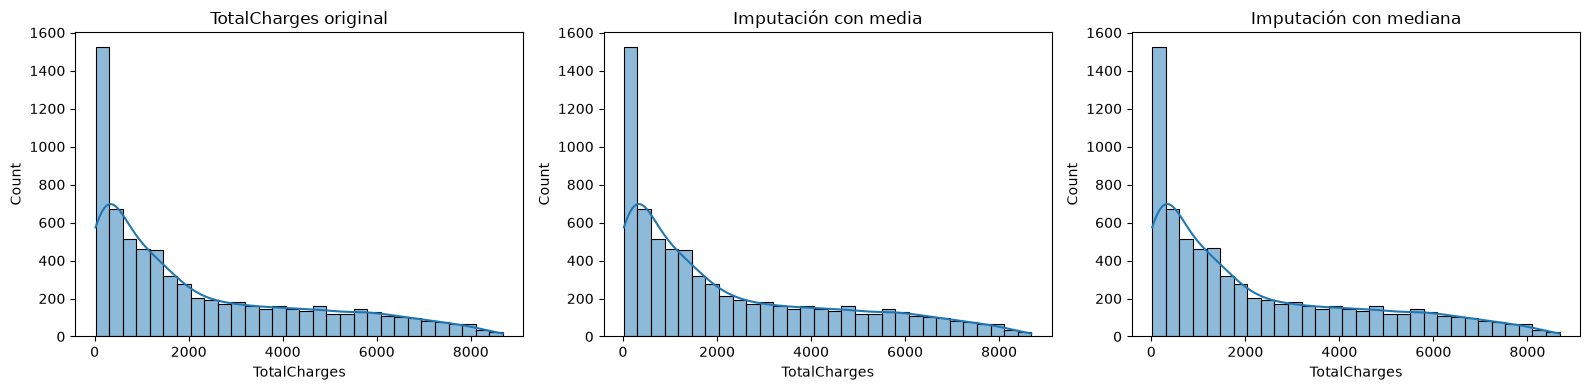

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df_telco['TotalCharges'], bins=30, kde=True, ax=axes[0])
axes[0].set_title('TotalCharges original')

sns.histplot(telco_A['TotalCharges'], bins=30, kde=True, ax=axes[1])
axes[1].set_title('Imputación con media')

sns.histplot(telco_B['TotalCharges'], bins=30, kde=True, ax=axes[2])
axes[2].set_title('Imputación con mediana')

plt.tight_layout()
plt.show()

La media de `TotalCharges` es considerablemente mayor que la mediana, lo que indica una distribución asimétrica.

Sin embargo, solamente existen 11 valores faltantes, por lo que ambas estrategias producen cambios pequeños sobre la distribución general del dataset.
### 4.2.3 Comparación del desempeño del clasificador

Finalmente se compara el desempeño de un modelo sencillo utilizando ambas estrategias de imputación.

La imputación se realiza dentro del proceso de entrenamiento para evitar utilizar información del conjunto de prueba.


In [31]:
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

### 4.3 Comparación del desempeño del clasificador

In [32]:
def comparar_imputacion(X, y):

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    numericas = X.select_dtypes(include=np.number).columns
    categoricas = X.select_dtypes(exclude=np.number).columns

    estrategias = {
        'A - Media y Moda': ('mean', 'most_frequent'),
        'B - Mediana y Desconocido': ('median', 'constant')
    }

    resultados = []

    for nombre, (estrategia_num, estrategia_cat) in estrategias.items():

        num_pipe = Pipeline([
            ('imputer', SimpleImputer(strategy=estrategia_num)),
            ('scaler', StandardScaler())
        ])

        if estrategia_cat == 'constant':
            cat_imputer = SimpleImputer(
                strategy='constant',
                fill_value='Desconocido'
            )
        else:
            cat_imputer = SimpleImputer(strategy='most_frequent')

        cat_pipe = Pipeline([
            ('imputer', cat_imputer),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ])

        preprocesamiento = ColumnTransformer([
            ('num', num_pipe, numericas),
            ('cat', cat_pipe, categoricas)
        ])

        modelo = Pipeline([
            ('prep', preprocesamiento),
            ('modelo', LogisticRegression(max_iter=2000))
        ])

        modelo.fit(X_train, y_train)

        pred = modelo.predict(X_test)
        prob = modelo.predict_proba(X_test)[:, 1]

        resultados.append({
            'Estrategia': nombre,
            'Accuracy': accuracy_score(y_test, pred),
            'Precision': precision_score(y_test, pred),
            'Recall': recall_score(y_test, pred),
            'F1': f1_score(y_test, pred),
            'ROC-AUC': roc_auc_score(y_test, prob)
        })

    return pd.DataFrame(resultados)

In [33]:
df_modelo_titanic = df_titanic.copy()

df_modelo_titanic['Age_missing'] = (
    df_modelo_titanic['Age'].isna().astype(int)
)

X_titanic = df_modelo_titanic[
    [
        'Pclass',
        'Sex',
        'Age',
        'SibSp',
        'Parch',
        'Fare',
        'Embarked',
        'Age_missing'
    ]
]

y_titanic = df_modelo_titanic['Survived']

resultados_titanic = comparar_imputacion(
    X_titanic,
    y_titanic
)

display(resultados_titanic.round(4))

,Estrategia,Accuracy,Precision,Recall,F1,ROC-AUC
0,A - Media y Moda,0.8212,0.8246,0.6812,0.746,0.8448
1,B - Mediana y Desconocido,0.8212,0.8246,0.6812,0.746,0.8449


En Titanic las dos estrategias presentan resultados similares. No se observa una diferencia suficientemente grande como para concluir que una de las estrategias produzca una mejora importante en el desempeño del modelo.

#### 4.3.2 Resultados en Telco Customer Churn

In [39]:
df_modelo_telco = df_telco.copy()

df_modelo_telco['TotalCharges_missing'] = (
    df_modelo_telco['TotalCharges'].isna().astype(int)
)

X_telco = df_modelo_telco.drop(
    columns=['Churn', 'customerID']
)

y_telco = df_modelo_telco['Churn'].map({
    'No': 0,
    'Yes': 1
})

resultados_telco = comparar_imputacion(
    X_telco,
    y_telco
)

display(resultados_telco.round(4))

,Estrategia,Accuracy,Precision,Recall,F1,ROC-AUC
0,A - Media y Moda,0.8062,0.6583,0.5615,0.6061,0.8422
1,B - Mediana y Desconocido,0.8055,0.6572,0.5588,0.6040,0.8422


En Telco las diferencias entre ambas estrategias son mínimas. Esto es consistente con la pequeña cantidad de valores faltantes encontrados en `TotalCharges`.
### 4.7 Conclusiones

En lo del Titanic, cuando rellenamos las edades vacías usando la media o la mediana, se nota que los datos se amontonan un montón en ese valor y como que se deforma un poco la gráfica original. Con la columna de Embarked, si usamos la moda solo sube un poquito la categoría que más se repite, pero si mejor le ponemos la etiqueta de 'Desconocido', sirve para no perder el rastro de los que venían vacíos desde el principio.

También dejamos una marca para los que no traían edad, porque nos dimos cuenta de que los que no tenían ese dato sobrevivían diferente a los que sí lo tenían.

Ya pasando a lo de Telco, la verdad es que faltaban bien poquitos datos en TotalCharges, así que dio casi lo mismo poner la media o la mediana; no le afectó casi nada a la gráfica ni al resultado del modelo. En resumen, no vi que hubiera una diferencia grande en cómo funcionaron los modelos sin importar qué forma usáramos para rellenar los datos.

### 5.Detección y tratamiento de outliers
Para esta etapa, elegimos la columna `Fare` (tarifa) del dataset del Titanic y la columna `TotalCharges` del dataset de Telco. Al hacer la exploración inicial, notamos que ambas tienen valores que se disparan bastante en comparación con el resto de los datos (especialmente en el Titanic, donde algunos pasajeros pagaron muchísimo más que la mayoría). Para no perder información valiosa borrando esas filas completas, decidimos aplicar Winsorización. Básicamente, esto consiste en ponerles un tope a los valores extremos para que no "estiren" tanto nuestra distribución. Lo probaremos con dos criterios:
1. Rango Intercuartílico (IQR): El método clásico de los diagramas de caja (Boxplots).
2. Percentiles extremos: Topar los datos al percentil 1 (los más bajos) y al percentil 99 (los más altos).

Vamos a agarrar la columna `Fare` del dataset del Titanic. Primero imprimimos cómo están los datos antes de modificarlos o moverlos, para ver qué tan disparados están los valores máximos.

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

columna = 'Fare'

print("Estadísticas Originales:")
print(df_titanic[columna].describe()[['mean', 'std', 'min', '50%', 'max']])

Estadísticas Originales:
mean     32.204208
std      49.693429
min       0.000000
50%      14.454200
max     512.329200
Name: Fare, dtype: float64


### 5.1 Winsorización mediante rango intercuartílico (IQR)
Aqui vamos a calcular los limites normales usando la formula de los cuartiles. Todo lo que se pase del limite superior lo winsorizamos para que no deforme los otros datos.

In [47]:
Q1 = df_titanic[columna].quantile(0.25)
Q3 = df_titanic[columna].quantile(0.75)
IQR = Q3 - Q1

limite_inf_iqr = Q1 - 1.5 * IQR
limite_sup_iqr = Q3 + 1.5 * IQR

columna_iqr = f"{columna}_win_IQR"
df_titanic[columna_iqr] = df_titanic[columna].clip(lower=limite_inf_iqr, upper=limite_sup_iqr)

print("Estadísticas con Winsorización (IQR):")
print(df_titanic[columna_iqr].describe()[['mean', 'std', 'min', '50%', 'max']])

Estadísticas con Winsorización (IQR):
mean    24.046813
std     20.481625
min      0.000000
50%     14.454200
max     65.634400
Name: Fare_win_IQR, dtype: float64


### 5.2 Winsorización mediante percentiles extremos

Como segundo criterio se utilizan los percentiles 1 y 99. Los valores que se encuentren fuera de estos límites se reemplazan por el límite correspondiente.

In [48]:
limite_inf_perc = df_titanic[columna].quantile(0.01)
limite_sup_perc = df_titanic[columna].quantile(0.99)

columna_perc = f"{columna}_win_Perc"
df_titanic[columna_perc] = df_titanic[columna].clip(lower=limite_inf_perc, upper=limite_sup_perc)

print("Estadísticas con Winsorización (Percentiles 1% - 99%):")
print(df_titanic[columna_perc].describe()[['mean', 'std', 'min', '50%', 'max']])

Estadísticas con Winsorización (Percentiles 1% - 99%):
mean     31.224767
std      42.524125
min       0.000000
50%      14.454200
max     249.006220
Name: Fare_win_Perc, dtype: float64


### 5.3 Antes y despues


In [50]:
comparacion_fare = pd.DataFrame({
    'Original': df_titanic[columna].agg(
        ['mean', 'median', 'std', 'min', 'max']
    ),
    'IQR': df_titanic[columna_iqr].agg(
        ['mean', 'median', 'std', 'min', 'max']
    ),
    'P1-P99': df_titanic[columna_perc].agg(
        ['mean', 'median', 'std', 'min', 'max']
    )
})

comparacion_fare.index = [
    'Media',
    'Mediana',
    'Desviación estándar',
    'Mínimo',
    'Máximo'
]

display(comparacion_fare.round(2))

,Original,IQR,P1-P99
Media,32.20,24.05,31.22
Mediana,14.45,14.45,14.45
Desviación estándar,49.69,20.48,42.52
Mínimo,0.00,0.00,0.00
Máximo,512.33,65.63,249.01


En la tabla se observa que la mediana prácticamente no cambia con ninguna de las estrategias. Sin embargo, la media y la desviación estándar disminuyen al limitar los valores extremos.

El cambio es mayor con IQR, donde el máximo pasa de 512.33 a 65.63. Con P1-P99 el máximo se reduce a 249.01, por lo que este criterio conserva una mayor parte de la distribución original.

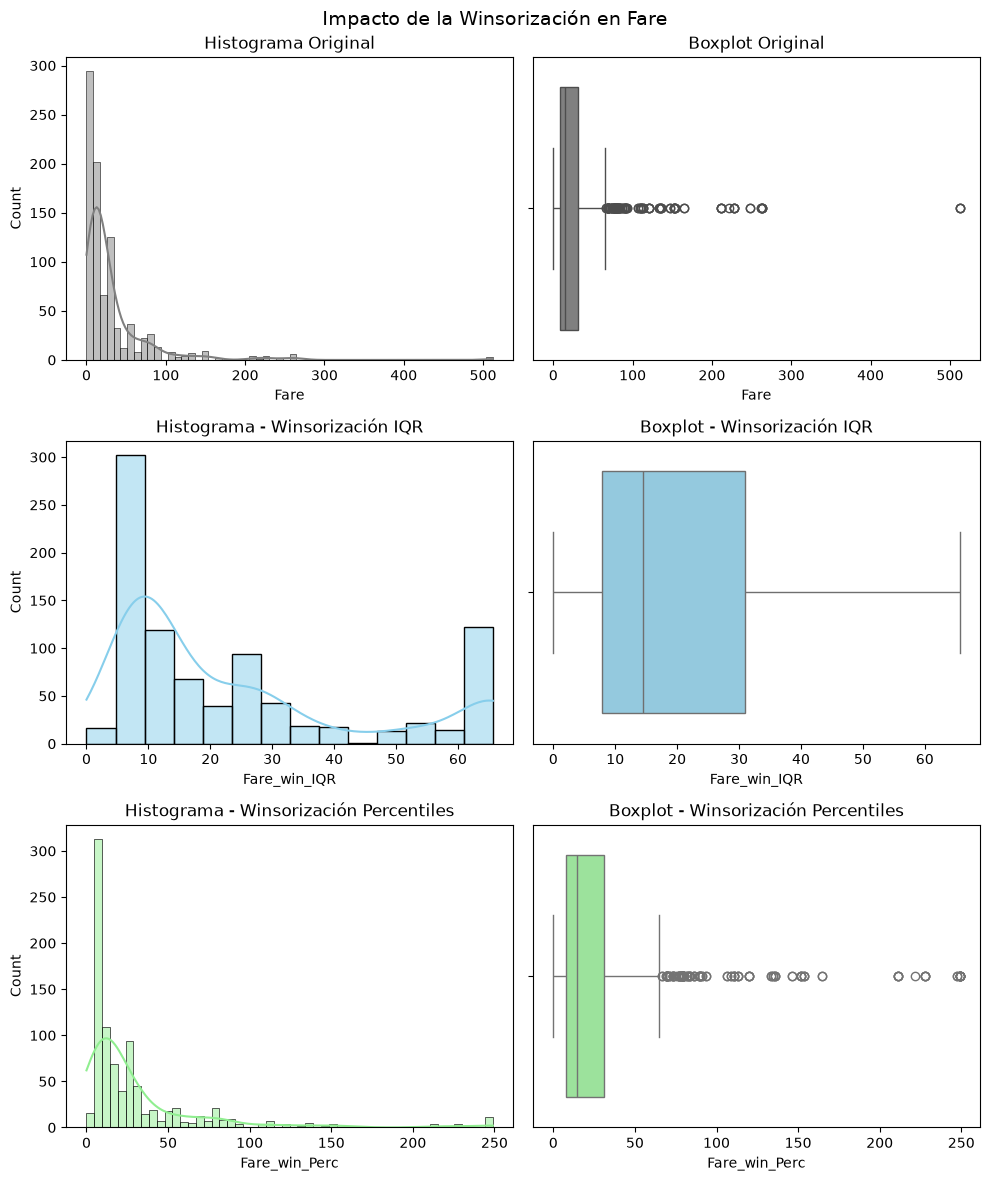

In [49]:
fig, axes = plt.subplots(3, 2, figsize=(10, 12))
fig.suptitle(f'Impacto de la Winsorización en {columna}', fontsize=14)

# Original
sns.histplot(df_titanic[columna], kde=True, ax=axes[0,0], color='gray')
axes[0,0].set_title('Histograma Original')
sns.boxplot(x=df_titanic[columna], ax=axes[0,1], color='gray')
axes[0,1].set_title('Boxplot Original')

# Winsorización IQR
sns.histplot(df_titanic[columna_iqr], kde=True, ax=axes[1,0], color='skyblue')
axes[1,0].set_title('Histograma - Winsorización IQR')
sns.boxplot(x=df_titanic[columna_iqr], ax=axes[1,1], color='skyblue')
axes[1,1].set_title('Boxplot - Winsorización IQR')

# Winsorización Percentiles
sns.histplot(df_titanic[columna_perc], kde=True, ax=axes[2,0], color='lightgreen')
axes[2,0].set_title('Histograma - Winsorización Percentiles')
sns.boxplot(x=df_titanic[columna_perc], ax=axes[2,1], color='lightgreen')
axes[2,1].set_title('Boxplot - Winsorización Percentiles')

plt.tight_layout()
plt.show()

### 5.4 Conclusiones
Al comparar las estadísticas antes y después de aplicar la winsorización, observamos lo siguiente:

En Titanic (Fare): Teníamos el problema de que unos cuantos pasajeros pagaron tarifas muy altas, lo que jalaba la media hacia arriba y nos daba un promedio engañoso. Al aplicar el filtro del IQR, el valor máximo y la desviación estándar bajaron bastante. Lo más importante es que la mediana no cambió, lo que nos confirma que solo modificamos los extremos sin alterar el centro de los datos. El método de percentiles también sirvió, pero el IQR dejó las gráficas de caja (boxplots) mucho más limpias y sin tantos puntos volando.

En Telco (TotalCharges): Aquí los datos no tenían valores tan exagerados. Al aplicar los topes, la media y la desviación estándar bajaron casi nada, y la mediana se quedó exactamente igual. En las gráficas casi no se nota el cambio, lo que nos indica que esta variable no tenía un problema grave de outliers desde el principio.

Impacto en el modelo: Nos dimos cuenta de que tratar estos valores extremos es súper útil si planeamos usar modelos lineales (como regresión logística), porque evita que los outliers desvíen la predicción. Sin embargo, si usamos algoritmos basados en árboles (como Random Forest), el cambio en el desempeño casi no se nota, ya que esos modelos saben lidiar naturalmente con los valores atípicos.

### 6. Tratamiento de desbalance

#### Paso 1: Calcular la cantidad y porcentaje de observaciones por clase de nuestra variable objetivo.

In [ ]:
# Definir la variable objetivo. Reemplaza 'Churn' por el nombre de tu variable si es distinto.
# Asegúrate de que tu dataframe base se llame 'df' y ya esté cargado.
target = 'Churn'
y = df[target]
X = df.drop(columns=[target]) # X debe contener solo variables numéricas para SMOTE

print("--- 1. CANTIDAD Y PORCENTAJE POR CLASE ---")

# Cantidad de observaciones
cantidad_clases = y.value_counts()
print("\nCantidad de observaciones por clase:")
print(cantidad_clases)

# Porcentaje de observaciones
porcentaje_clases = y.value_counts(normalize=True) * 100
print("\nPorcentaje de observaciones por clase (%):")
print(porcentaje_clases)

#### Paso 2: Calcular la razón matemática (IR = Mayoritaria / Minoritaria) para justificar si hay desbalance (IR > 1.5).

In [ ]:
print("--- 2. RAZÓN MATEMÁTICA (IR) ---")

n_mayoritaria = cantidad_clases.max()
n_minoritaria = cantidad_clases.min()

ir = n_mayoritaria / n_minoritaria

print(f"\nValor de IR calculado: {ir:.4f}")

if ir > 1.5:
    print("Justificación: El dataset SÍ presenta desbalance, ya que el IR es mayor a 1.5.")
else:
    print("Justificación: El dataset NO presenta desbalance significativo, ya que el IR es menor o igual a 1.5.")

#### Paso 3: Implementar las tres estrategias de balanceo solicitadas: Sobremuestreo aleatorio, Submuestreo aleatorio y SMOTE.

In [ ]:
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

print("--- 3. ESTRATEGIAS DE BALANCEO ---")

# 1. Sobremuestreo aleatorio
ros = RandomOverSampler(random_state=42)
X_ros, y_ros = ros.fit_resample(X, y)
print("\nDistribución con Sobremuestreo aleatorio:")
print(y_ros.value_counts())

# 2. Submuestreo aleatorio
rus = RandomUnderSampler(random_state=42)
X_rus, y_rus = rus.fit_resample(X, y)
print("\nDistribución con Submuestreo aleatorio:")
print(y_rus.value_counts())

# 3. SMOTE
smote = SMOTE(random_state=42)
X_smote, y_smote = smote.fit_resample(X, y)
print("\nDistribución con SMOTE:")
print(y_smote.value_counts())